# Лабораторная работа 2. Два класса алгоритмов сортировки

**Опора:** лекции 3–5.

Реализуются **четыре сортировки**:

- пузырьковая — обязательно;
- сортировка подсчётом — обязательно;
- одна из трёх сортировок сравнением: быстрая, слиянием, пирамидальная;
- одна из двух сортировок без сравнений: поразрядная, блочная.

Задача у всех одна: **вход** — список чисел, **выход** — тот же список,
упорядоченный по неубыванию.

Нужно самостоятельно реализовать выбранные алгоритмы, не заменяя их вызовами
готовых сортировок. Конкретный вариант реализации выбирает студент.

In [3]:
import sys
from pathlib import Path

for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "labkit").is_dir():
        sys.path.insert(0, str(candidate))
        break

import labkit as lk

print("Режим:", lk.CONFIG.name, "| размеры массивов:", lk.sizes())

/Users/sonkxx/DSA_IDU_26/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Режим: быстрый | размеры массивов: [16, 32, 48, 64, 80, 96, 112, 128, 144, 160, 176, 192, 208, 224, 240, 256, 272, 288, 304, 320, 336, 352, 368, 384, 400, 416, 432, 448, 464, 480, 496, 512]


## Задача 1. Пузырьковая сортировка (обязательно)

Соседние элементы сравниваются и переставляются, пока массив не станет
упорядоченным.

Если полный проход не выполнил ни одного обмена, алгоритм должен завершиться.

In [5]:
def bubble_sort(arr):
    """Пузырьковая сортировка."""
    n = len(arr)

    for i in range(n):
        swapped = False

        for j in range(0, n - i - 1):
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
                swapped = True

        if not swapped:
            break

    return arr

   

In [6]:
lk.check_sort(bubble_sort, "Пузырьковая сортировка")
lk.check_early_exit(bubble_sort, "Досрочный выход")

Пузырьковая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

## Задача 2. Сортировка подсчётом (обязательно)

Подсчитывается, сколько раз встречается каждый ключ, после чего элементы
раскладываются по местам.

- **Вход:** неотрицательные целые числа.

In [7]:
def counting_sort(arr):
    """Сортировка подсчётом для неотрицательных целых чисел."""
    if len(arr) == 0:
        return []

    max_value = max(arr)
    counts = [0] * (max_value + 1)

    for num in arr:
        counts[num] += 1

    result = []

    for num in range(len(counts)):
        for _ in range(counts[num]):
            result.append(num)

    return result


In [8]:
lk.check_sort(counting_sort, "Сортировка подсчётом")

Сортировка подсчётом
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 100

## Выбор 1. Сортировка сравнением

Реализовать **одну** из трёх: быструю, слиянием или пирамидальную.

**Быстрая сортировка.** Разделение по опорному элементу. Способ выбора
опорного элемента определяет студент.

**Сортировка слиянием.** Разделение пополам и слияние упорядоченных частей.

**Пирамидальная сортировка.** Реализацию разделить на три функции:

- `_sift_down(arr, start, size)` восстанавливает свойство max-heap в поддереве;
- `_build_max_heap(arr)` строит max-heap снизу вверх;
- `heap_sort(arr)` сначала строит кучу, затем последовательно извлекает максимум.

In [9]:
def quick_sort(arr):
    """Быстрая сортировка."""
    if len(arr) <= 1:
        return arr.copy()

    pivot = arr[len(arr) // 2]

    left = [x for x in arr if x < pivot]
    middle = [x for x in arr if x == pivot]
    right = [x for x in arr if x > pivot]

    return quick_sort(left) + middle + quick_sort(right)

In [10]:
lk.check_sort(quick_sort, "Быстрая сортировка", optional=True)

Быстрая сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1000,

In [ ]:
def merge_sort(arr):
    """Сортировка слиянием."""
    # TODO: реализовать, если выбрана сортировка слиянием
    raise NotImplementedError("merge_sort")

In [ ]:
lk.check_sort(merge_sort, "Сортировка слиянием", optional=True)

In [ ]:
def _sift_down(arr, start, size):
    """Восстановить свойство max-heap в поддереве с корнем start."""
    # TODO: реализовать просеивание вниз
    raise NotImplementedError("_sift_down")


def _build_max_heap(arr):
    """Построить max-heap снизу вверх."""
    # TODO: реализовать построение кучи
    raise NotImplementedError("_build_max_heap")


def heap_sort(arr):
    """Пирамидальная сортировка с предварительным построением max-heap."""
    # TODO: построить кучу и последовательно извлечь максимумы
    raise NotImplementedError("heap_sort")

In [ ]:
lk.check_sort(heap_sort, "Пирамидальная сортировка", optional=True)

## Выбор 2. Сортировка без сравнений

Реализовать **одну** из двух.

**Поразрядная сортировка.** Обработка чисел по разрядам. Конкретную схему
выбирает студент; результат должен быть упорядочен по неубыванию.

- **Вход:** неотрицательные целые числа.

In [11]:
def radix_sort(arr):
    """Поразрядная сортировка для неотрицательных целых чисел."""
    if len(arr) <= 1:
        return arr.copy()

    result = arr.copy()
    max_num = max(result)

    exp = 1

    while max_num // exp > 0:
        output = [0] * len(result)
        count = [0] * 10

        for num in result:
            digit = (num // exp) % 10
            count[digit] += 1

        for i in range(1, 10):
            count[i] += count[i - 1]

        for i in range(len(result) - 1, -1, -1):
            digit = (result[i] // exp) % 10
            output[count[digit] - 1] = result[i]
            count[digit] -= 1

        result = output
        exp *= 10

    return result

In [12]:
lk.check_sort(radix_sort, "Поразрядная сортировка", optional=True)

Поразрядная сортировка
  [ok]   пустой массив
    Input: []
    Output: []
    Expected: []
  [ok]   один элемент
    Input: [5]
    Output: [5]
    Expected: [5]
  [ok]   два элемента по порядку
    Input: [1, 2]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   два элемента наоборот
    Input: [2, 1]
    Output: [1, 2]
    Expected: [1, 2]
  [ok]   уже отсортирован
    Input: [1, 2, 3, 4, 5]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   обратно отсортирован
    Input: [5, 4, 3, 2, 1]
    Output: [1, 2, 3, 4, 5]
    Expected: [1, 2, 3, 4, 5]
  [ok]   повторяющиеся элементы
    Input: [3, 1, 2, 3, 2, 1]
    Output: [1, 1, 2, 2, 3, 3]
    Expected: [1, 1, 2, 2, 3, 3]
  [ok]   все элементы одинаковые
    Input: [7, 7, 7, 7]
    Output: [7, 7, 7, 7]
    Expected: [7, 7, 7, 7]
  [ok]   содержит ноль
    Input: [0, 5, 0, 3, 1]
    Output: [0, 0, 1, 3, 5]
    Expected: [0, 0, 1, 3, 5]
  [ok]   большие значения
    Input: [9999, 10, 500, 1000, 1]
    Output: [1, 10, 500, 1

**Блочная сортировка.** Значения распределяются по блокам, каждый блок
сортируется отдельно, после чего блоки соединяются по порядку.

- **Вход:** вещественные числа из полуинтервала `[0, 1)`.

In [19]:
def bucket_sort(arr):
    """Блочная сортировка вещественных чисел из [0, 1)."""
    # TODO: реализовать, если выбрана блочная сортировка
    raise NotImplementedError("bucket_sort")

In [20]:
lk.check_sort(bucket_sort, "Блочная сортировка", floats=True, optional=True)

Блочная сортировка: вариант не выбран, тесты пропущены


## Набор реализованных сортировок

Дальше всё считается по тем реализациям, которые действительно написаны.

In [22]:
INT_SORTS = lk.implemented_sorts({
    "пузырьковая": bubble_sort,
    "подсчётом": counting_sort,
    "быстрая": quick_sort,
    "поразрядная": radix_sort,
})

In [28]:
sorting = lk.sorting_table(
    INT_SORTS, FLOAT_SORTS, samples=5, repeats=5,
)

Размер входа: все метрики: 100%|██████████| 640/640 [00:02<00:00, 292.24опыт/s, Размер входа; поразрядная; Случайный; n=512; вход 5/5]


## Эксперимент 1. Все сортировки вместе

Случайный вход одного и того же набора значений для всех сортировок.

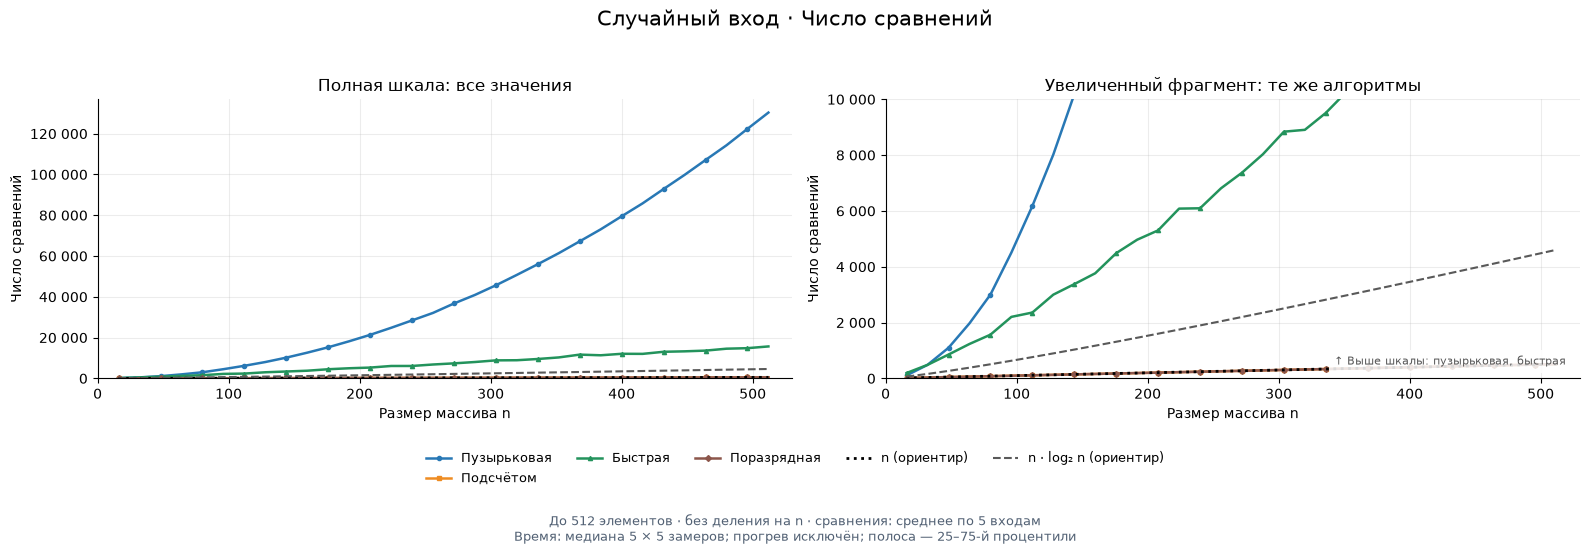

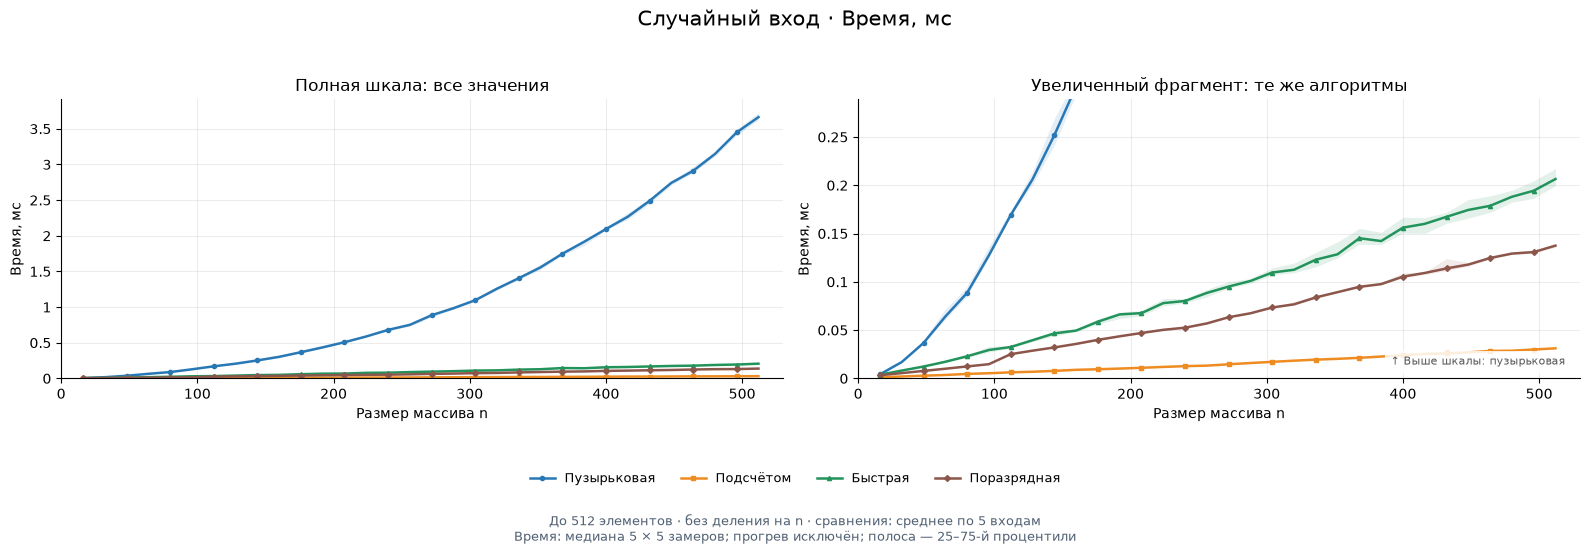

In [29]:
lk.plot_overview(sorting);

## Эксперимент 2. Пространство ключей

Размер массива зафиксирован: `n = 512`. Меняется размер пространства ключей
`k`: элементы случайно выбираются из полуинтервала `[0, k)`. В каждый вход
добавляется ключ `k - 1`, поэтому фактический диапазон не сужается случайно.
Блочная сортировка получает те же ключи, нормированные в диапазон `[0, 1)`.

Результаты разделены по типу алгоритмов:

- для сортировок на сравнениях верхний ряд показывает число сравнений между
  элементами, нижний — время;
- для сортировок, основанных на распределении, верхний ряд показывает число
  выполненных шагов циклов в коде алгоритма и его вспомогательных функций,
  нижний — время.

Один шаг цикла не равен одной машинной операции. Новый счётчик нужен для
сравнения формы зависимостей от `k`, а не абсолютной скорости разных
реализаций.

In [26]:
keyspace = lk.keyspace_table(
    INT_SORTS, FLOAT_SORTS, n=512, samples=5, repeats=5,
)

Пространство ключей: время и работа: 100%|██████████| 260/260 [00:08<00:00, 29.66опыт/s, Пространство ключей; поразрядная; k = 1048576; k=1048576; вход 5/5]


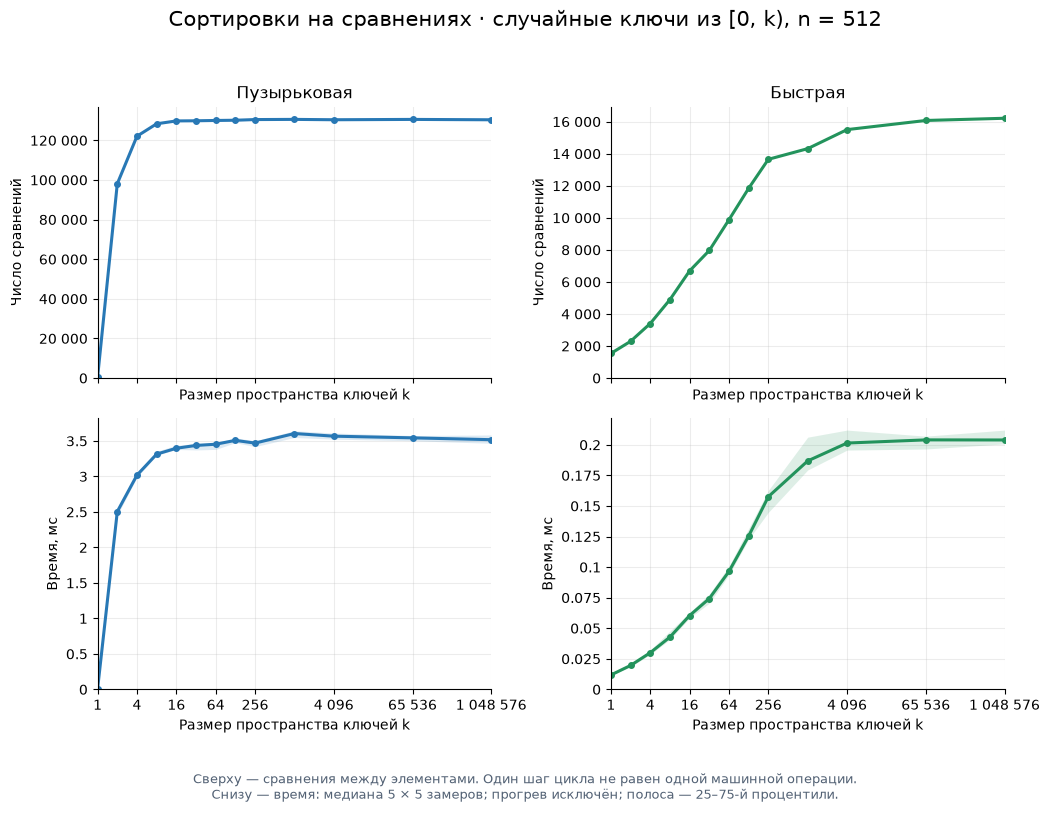

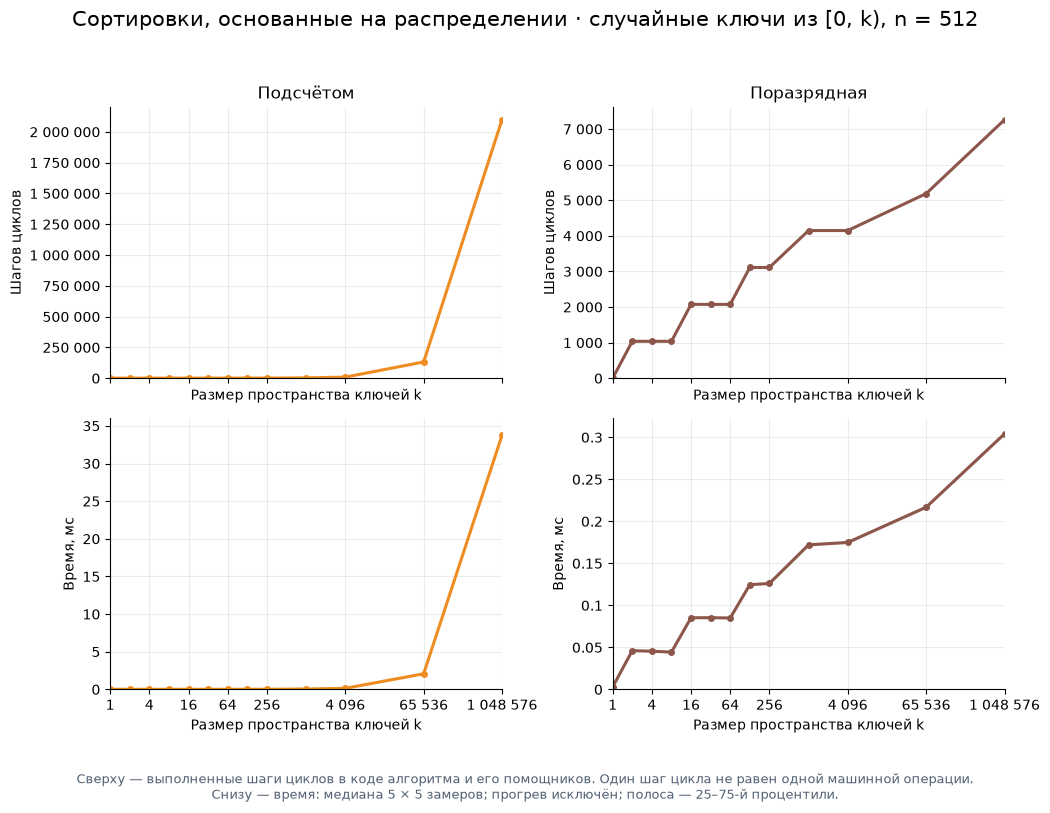

In [27]:
lk.plot_keyspace(keyspace);

## Самостоятельные выводы

Сформулируйте выводы по своим графикам и объясните их устройством реализаций.

1. Почему при увеличении `n` пузырьковая сортировка начинает заметно уступать
   выбранной сортировке сравнением? Какие части алгоритмов определяют форму их
   кривых?
   Когда увеличивается размер массива, пузырьковая сортировка начинает работать намного медленнее. Это происходит потому, что ей приходится много раз сравнивать соседние элементы и менять их местами. Поэтому на больших массивах она работает не очень быстро.
2. Почему сортировки подсчётом, поразрядная и блочная могут обходиться без
   `n log n` сравнений? Какие ограничения на входные данные позволяют им это
   делать?
   Сортировка подсчётом, поразрядная и блочная сортировки могут работать без сравнений между элементами. Они используют другие способы сортировки. Например, сортировка подсчётом считает, сколько раз встречается каждое число. Но у таких алгоритмов есть ограничения: они подходят не для всех типов данных.
3. Что особенного происходит при `k = 1`, когда все элементы равны? Какие
   алгоритмы могут завершать отдельные этапы раньше, а какие продолжают
   выполнять почти всю предусмотренную работу?
   Если все элементы массива одинаковые, некоторые алгоритмы могут быстрее закончить свою работу. Например, пузырьковая сортировка не будет делать обмены, а быстрая сортировка может работать не так эффективно, в зависимости от выбора опорного элемента.
4. Как повторяющиеся ключи влияют на выбранную сортировку сравнением: на обмены
   пузырьковой сортировки, разбиение быстрой сортировки, слияние или
   восстановление кучи?
   Если в массиве много одинаковых чисел, это может влиять на скорость сортировки. Например, быстрая сортировка может тратить больше времени на обработку повторяющихся элементов. Другие алгоритмы, например сортировка слиянием, работают более стабильно.
5. Если выбрана поразрядная сортировка, почему изменение времени связано с
   числом разрядов? Если выбрана блочная — как распределение элементов по
   блокам влияет на стоимость внутренней сортировки?
   Для поразрядной сортировки важно количество цифр в числах, потому что она сортирует числа по отдельным разрядам. А блочная сортировка зависит от того, как элементы распределяются по блокам. Если распределение неудачное, сортировка может работать медленнее.
6. Какие различия на графиках следуют из общей идеи алгоритма, а какие могут
   измениться при другом выборе опорного элемента, условии досрочного выхода
   или способе сортировки блоков?
   По графикам видно, что разные алгоритмы ведут себя по-разному. Одни быстрее работают на больших массивах, другие лучше подходят для определённых видов данных. Поэтому нельзя сказать, что один алгоритм всегда самый лучший. Всё зависит от размера массива и самих данных.